[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/fingerprint-similarity-guide/blob/main/notebooks/01_what_is_a_fingerprint.ipynb)

# 01 · What a Molecular Fingerprint Is

*Fingerprint & Similarity Guide · Hamza Hentabli, Ph.D. · ~35 min*

Before comparing molecules we have to *encode* them. A **molecular fingerprint** turns a structure into a fixed vector of bits (or counts) that captures which substructures are present. Everything else in this course — similarity, screening, clustering, QSAR — stands on this one idea, so we start by looking at what is actually inside a fingerprint.

**Learning objectives.** By the end of this notebook you will be able to:

- explain what the bits in a fingerprint mean
- generate a Morgan (ECFP-like) fingerprint and inspect its on-bits
- see how **folding** to a fixed length causes bit **collisions**
- tell the difference between **binary** and **count** fingerprints

In [1]:
# Setup: on Google Colab this installs dependencies and clones the repo so the
# cached data and the shared `fsg` helper module are available. Running locally,
# install requirements.txt once and this cell just locates the files.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("FSG_OFFLINE", "0") == "1"   # CI sets this; no notebook needs the network
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "rdkit", "scikit-learn", "scipy", "pandas", "matplotlib"], check=True)
    if not os.path.isdir("fingerprint-similarity-guide"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/fingerprint-similarity-guide.git"], check=True)
    ROOT = "fingerprint-similarity-guide"
else:
    ROOT = ".." if os.path.isdir("../data") else "."
DATA_DIR = os.path.join(ROOT, "data")
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
import fsg   # shared fingerprint factory + metrics + evaluation

print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| data:", DATA_DIR)
print("Fingerprints available:", ", ".join(fsg.FP_NAMES))

Colab: False | offline: True | data: ../data
Fingerprints available: ECFP4-1024, ECFP4-2048, ECFP6-2048, ECFP4-counts, FCFP4-2048, RDKit, AtomPair, Torsion, MACCS, Avalon


## 1. A molecule becomes a vector of bits

A structural fingerprint asks, for each of many substructure *features*, "is this feature present?" and records a 1 or 0. The **Morgan** fingerprint (a.k.a. ECFP) enumerates each atom's circular neighbourhood out to a given **radius**, hashes each environment to a number, and sets that bit. Let's build one for gefitinib, an approved EGFR inhibitor.

length: 2048 bits
bits set to 1: 60
first on-bits: [13, 80, 191, 216, 249, 329, 366, 378, 465, 489, 491, 523]


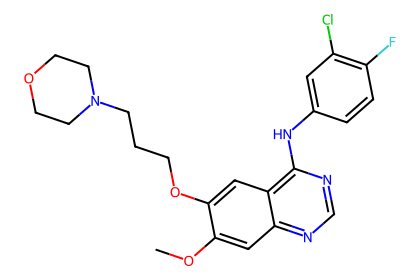

In [2]:
from rdkit import Chem
from rdkit.Chem import Draw, rdFingerprintGenerator

gefitinib = Chem.MolFromSmiles("COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1")
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fp = mfpgen.GetFingerprint(gefitinib)
print("length:", fp.GetNumBits(), "bits")
print("bits set to 1:", fp.GetNumOnBits())
print("first on-bits:", list(fp.GetOnBits())[:12])
Draw.MolToImage(gefitinib, size=(420, 280))

Only a small fraction of the 2,048 bits are on — a fingerprint is **sparse**. Each on-bit says "a particular atomic environment occurs in this molecule."

## 2. Which substructure does a bit stand for?

Morgan bits are interpretable: we can ask RDKit which atom + radius produced each bit.

In [3]:
bi = {}
fp2 = mfpgen.GetFingerprint(gefitinib, additionalOutput=None)
# recompute capturing bit info
from rdkit.Chem import rdFingerprintGenerator as rfg
ao = rfg.AdditionalOutput(); ao.AllocateBitInfoMap()
fp3 = mfpgen.GetFingerprint(gefitinib, additionalOutput=ao)
bitinfo = ao.GetBitInfoMap()
some_bits = list(bitinfo.keys())[:5]
print("bit -> list of (atom index, radius):")
for b in some_bits:
    print(f"  bit {b}: {bitinfo[b]}")

bit -> list of (atom index, radius):
  bit 13: ((22, 1),)
  bit 80: ((22, 0), (23, 0), (24, 0))
  bit 191: ((10, 1),)
  bit 216: ((12, 2),)
  bit 249: ((1, 2),)


Each on-bit maps back to one or more (atom, radius) environments in the molecule — proof that fingerprints encode concrete chemistry, not magic numbers.

## 3. Folding and bit collisions

The Morgan algorithm first produces a huge, essentially unique integer for every environment. To get a fixed-length vector those integers are **folded** (hashed modulo the length). Two different environments can then land on the **same bit** — a *collision*. Shorter fingerprints collide more.

In [4]:
def collisions(mol, fpsize):
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=fpsize)
    ao = rfg.AdditionalOutput(); ao.AllocateBitInfoMap()
    gen.GetFingerprint(mol, additionalOutput=ao)
    bi = ao.GetBitInfoMap()
    n_env = sum(len(v) for v in bi.values())
    n_bits = len(bi)
    collided = sum(1 for v in bi.values() if len(v) > 1)
    return n_env, n_bits, collided

for size in [512, 1024, 2048, 4096]:
    env, bits, col = collisions(gefitinib, size)
    print(f"fpSize={size:5d}: {env} environments -> {bits} bits set, {col} bits hold >1 environment")

fpSize=  512: 90 environments -> 59 bits set, 15 bits hold >1 environment
fpSize= 1024: 90 environments -> 60 bits set, 14 bits hold >1 environment
fpSize= 2048: 90 environments -> 60 bits set, 14 bits hold >1 environment
fpSize= 4096: 90 environments -> 61 bits set, 14 bits hold >1 environment


Fewer bits ⇒ more environments crammed onto the same bit ⇒ information loss. Notebook 08 measures what this costs on a real benchmark.

## 4. Binary vs count fingerprints

A **binary** fingerprint records only *whether* a feature appears. A **count** fingerprint records *how many times*. Counts keep more information (e.g. three amide groups vs one).

In [5]:
mol = Chem.MolFromSmiles("O=C(N)CCC(=O)NCCC(=O)N")  # three amide-like groups
b = mfpgen.GetFingerprint(mol)
c = mfpgen.GetCountFingerprint(mol)
nz = c.GetNonzeroElements()
multi = {k: v for k, v in nz.items() if v > 1}
print("binary on-bits:", b.GetNumOnBits())
print("count bits with value > 1:", len(multi), "->", dict(list(multi.items())[:5]))

binary on-bits: 19
count bits with value > 1: 9 -> {80: 4, 140: 2, 545: 2, 650: 3, 807: 3}


The binary version collapses repeats to a single 1; the count version remembers them. Notebook 07 shows count fingerprints winning a QSAR benchmark for exactly this reason.

## Summary

- A fingerprint encodes **which substructures** a molecule contains as a fixed vector.
- Morgan/ECFP bits are **interpretable** (atom + radius) and **sparse**.
- **Folding** to a fixed length causes **collisions**; longer fingerprints collide less.
- **Count** fingerprints keep multiplicity that **binary** ones discard.

Next: generate the whole zoo of fingerprints on the same molecule and see how differently they behave.

### ✏️ Exercise 1

Build Morgan fingerprints of gefitinib at `fpSize` 256 and 2048 and print the number of colliding bits for each. Which collides more, and why?

<details>
<summary><b>Show solution</b></summary>

```python
for size in [256, 2048]:
    env, bits, col = collisions(gefitinib, size)
    print(size, "->", col, "colliding bits")
# 256 collides far more: fewer slots for the same environments.
```

</details>

### ✏️ Exercise 2

Compute the count fingerprint of caffeine (`CN1C=NC2=C1C(=O)N(C(=O)N2C)C`) and report the largest count on any single feature.

<details>
<summary><b>Show solution</b></summary>

```python
c = mfpgen.GetCountFingerprint(Chem.MolFromSmiles("CN1C=NC2=C1C(=O)N(C(=O)N2C)C"))
print(max(c.GetNonzeroElements().values()))
```

</details>